In [29]:
from omegaconf import OmegaConf
import matplotlib.pyplot as plt
import numpy as np

from bio_image_datasets.pannuke_dataset import PanNukeDataset
from bio_image_datasets.schuerch_dataset import SchuerchDataset
from bio_image_datasets.lizard_dataset import LizardDataset
from bio_image_datasets.arctique_dataset import ArctiqueDataset
from benchmark.utils import prep_datasets

In [2]:
pannuke_path = '/fast/AG_Kainmueller/data/pannuke'
pannuke_dataset = PanNukeDataset(pannuke_path)

LOCAL PATH /fast/AG_Kainmueller/data/pannuke


In [3]:
print(len(pannuke_dataset))
print(pannuke_dataset.get_he(0).shape)

7901
(3, 256, 256)


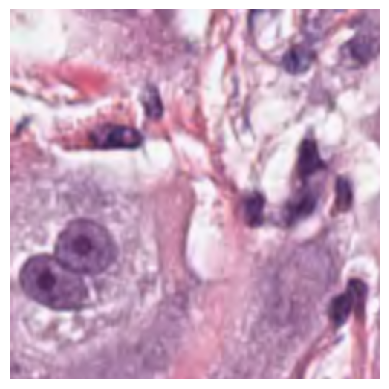

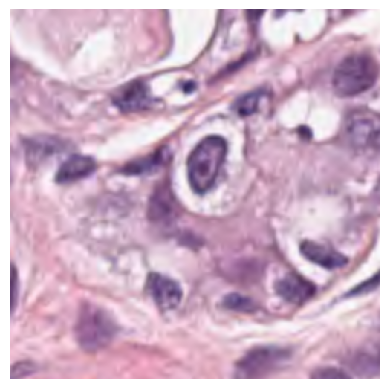

In [4]:
pannuke_img_0 = np.transpose(pannuke_dataset.get_he(0), (1, 2, 0))
pannuke_img_100 = np.transpose(pannuke_dataset.get_he(100), (1, 2, 0))

plt.imshow(pannuke_img_0 / 255.0)
plt.axis('off')
plt.show()
plt.imshow(pannuke_img_100 / 255.0)
plt.axis('off')
plt.show()

In [5]:
phenocell_path = '/fast/AG_Kainmueller/jrumber/data/SchuerchData/preprocessed/train'
phenocell_dataset = SchuerchDataset(phenocell_path)

In [6]:
print(len(phenocell_dataset))
print(phenocell_dataset.get_he(0).shape)

109
(3, 1440, 1920)


0
51750


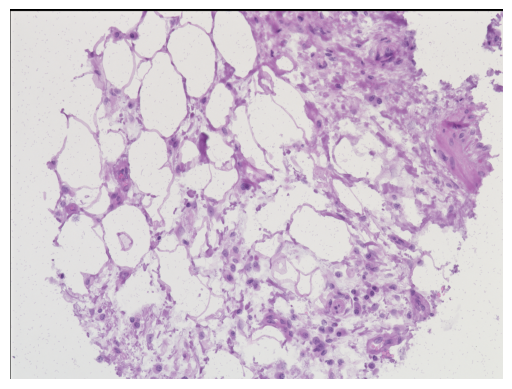

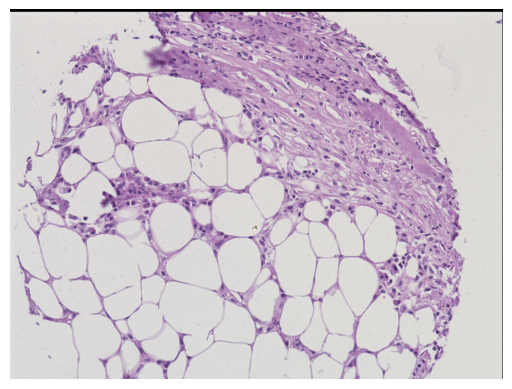

In [7]:
phenocell_img_0 = np.transpose(phenocell_dataset.get_he(0), (1, 2, 0))
phenocell_img_100 = np.transpose(phenocell_dataset.get_he(100), (1, 2, 0))

print(np.min(phenocell_img_0))
print(np.max(phenocell_img_0))

plt.imshow(phenocell_img_0 /np.max(phenocell_img_0))
plt.axis('off')
plt.show()
plt.imshow(phenocell_img_100 / np.max(phenocell_img_100))
plt.axis('off')
plt.show()

In [8]:
lizard_cfg_path = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/configs/config_unetr_lizard.yaml'
pannuke_cfg_path = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/configs/config_unetr_pannuke.yaml'
arctique_cfg_path = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/configs/config_unetr_arctique.yaml'
phenocell_cfg_path = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/configs/config_unetr_schuerch.yaml'

lizard_cfg = OmegaConf.load(lizard_cfg_path)
pannuke_cfg = OmegaConf.load(pannuke_cfg_path)
arctique_cfg = OmegaConf.load(arctique_cfg_path)
phenocell_cfg = OmegaConf.load(phenocell_cfg_path)

In [18]:
train_lizard, val_lizard, test_lizard, label_dict_lizard = prep_datasets(lizard_cfg)
train_pannuke, val_pannuke, test_pannuke, label_dict_pannuke = prep_datasets(pannuke_cfg)
train_arctique, val_arctique, test_arctique, label_dict_arctique = prep_datasets(arctique_cfg)
train_phenocell, val_phenocell, test_phenocell, label_dict_phenocell = prep_datasets(phenocell_cfg)

len_lizard = len(train_lizard)+len(val_lizard)+len(test_lizard)
len_pannuke = len(train_pannuke)+len(val_pannuke)+len(test_pannuke)
len_arctique = len(train_arctique)+len(val_arctique)+len(test_arctique)
len_phenocell = len(train_phenocell)+len(val_phenocell)+len(test_phenocell)

In [19]:
print(len_lizard)
print(len_pannuke)
print(len_arctique)
print(len_phenocell)

6454
31604
13050
6867


In [11]:
val_pannuke[0]

{'tile_name': 'fold1_0_TILE_0',
 'sample_name': 'fold1_0',
 'image': array([[[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]]], shape=(3, 224, 224)),
 'semantic_mask': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0,

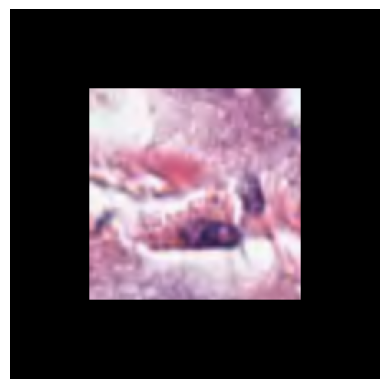

In [17]:
pannuke_tile_0 = np.transpose(val_pannuke[0]['image'], (1, 2, 0))
plt.imshow(pannuke_tile_0)
plt.axis('off')
plt.show()


In [23]:
count_instances_lizard = 0
for i in range(len(train_lizard)):
    n_instances = len(np.unique(train_lizard[i]['instance_mask']))
    count_instances_lizard = count_instances_lizard + n_instances
avg_instances_lizard = count_instances_lizard / len(train_lizard)
print(avg_instances_lizard)

64.020814479638


In [24]:
count_instances_pannuke = 0
for i in range(len(train_pannuke)):
    n_instances = len(np.unique(train_pannuke[i]['instance_mask']))
    count_instances_pannuke = count_instances_pannuke + n_instances
avg_instances_pannuke = count_instances_pannuke / len(train_pannuke)
print(avg_instances_pannuke)

8.260837619397503


In [25]:
count_instances_arctique = 0
for i in range(len(train_arctique)):
    n_instances = len(np.unique(train_arctique[i]['instance_mask']))
    count_instances_arctique = count_instances_arctique + n_instances
avg_instances_arctique = count_instances_arctique / len(train_arctique)
print(avg_instances_arctique)

38.37639710716634


In [26]:
count_instances_phenocell = 0
for i in range(len(train_phenocell)):
    n_instances = len(np.unique(train_phenocell[i]['instance_mask']))
    count_instances_phenocell = count_instances_phenocell + n_instances
avg_instances_phenocell = count_instances_phenocell / len(train_phenocell)
print(avg_instances_phenocell)

40.67996567996568


In [32]:
lizard_path = '/fast/AG_Kainmueller/data/patho_foundation_model_bench_data/lizard/original_data'
lizard_dataset = LizardDataset(lizard_path)

count_instances_lizard = 0
for i in range(len(lizard_dataset)):
    n_instances = len(np.unique(lizard_dataset.get_instance_mask(i)))
    count_instances_lizard = count_instances_lizard + n_instances
avg_instances_lizard = count_instances_lizard / len(lizard_dataset)
print(avg_instances_lizard)

1815.7605042016808


In [33]:
count_instances_pannuke = 0
for i in range(len(pannuke_dataset)):
    n_instances = len(np.unique(pannuke_dataset.get_instance_mask(i)))
    count_instances_pannuke = count_instances_pannuke + n_instances
avg_instances_pannuke = count_instances_pannuke / len(pannuke_dataset)
print(avg_instances_pannuke)

25.02354132388305


In [36]:
arctique_path = '/fast/AG_Kainmueller/data/patho_foundation_model_bench_data/arctique/raw_data'
arctique_dataset = ArctiqueDataset(arctique_path)

count_instances_arctique = 0
for i in range(len(arctique_dataset)):
    n_instances = len(np.unique(arctique_dataset.get_instance_mask(i)))
    count_instances_arctique = count_instances_arctique + n_instances
avg_instances_arctique = count_instances_arctique / len(arctique_dataset)
print(avg_instances_arctique)

LOCAL PATH /fast/AG_Kainmueller/data/patho_foundation_model_bench_data/arctique/raw_data
297.23241379310343


In [37]:
count_instances_phenocell = 0
for i in range(len(phenocell_dataset)):
    n_instances = len(np.unique(phenocell_dataset.get_instance_mask(i)))
    count_instances_phenocell = count_instances_phenocell + n_instances
avg_instances_phenocell = count_instances_phenocell / len(phenocell_dataset)
print(avg_instances_phenocell)

1997.2752293577983
